## Load and check data

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('../data/cleaned/books_cleaned.csv')

In [4]:
print(f"dataset shape: {df.shape}")
print(f"Name of the columns: {df.columns.tolist()}")
print(f"Head (first 5 rows):")
df.head()

dataset shape: (173, 7)
Name of the columns: ['title', 'category', 'book_url', 'image_url', 'description', 'image_path', 'title_description']
Head (first 5 rows):


,title,category,book_url,image_url,description,image_path,title_description
0,Private Paris (Private #10),Fiction,https://books.toscrape.com/catalogue/private-p...,https://books.toscrape.com/media/cache/9d/05/9...,Paris is burning--and only Private's Jack Morg...,images/book_1.jpg,Title: Private Paris (Private #10) Description...
1,"We Love You, Charlie Freeman",Fiction,https://books.toscrape.com/catalogue/we-love-y...,https://books.toscrape.com/media/cache/5f/15/5...,"The Freeman family--Charles, Laurel, and their...",images/book_2.jpg,"Title: We Love You, Charlie Freeman Descriptio..."
2,Thirst,Fiction,https://books.toscrape.com/catalogue/thirst_94...,https://books.toscrape.com/media/cache/c4/0a/c...,"On a searing summer Friday, Eddie Chapman has ...",images/book_3.jpg,Title: Thirst Description: On a searing summer...
3,The Murder That Never Was (Forensic Instincts #5),Fiction,https://books.toscrape.com/catalogue/the-murde...,https://books.toscrape.com/media/cache/dc/44/d...,"Given the opportunity, would you assume someon...",images/book_4.jpg,Title: The Murder That Never Was (Forensic Ins...
4,Tuesday Nights in 1980,Fiction,https://books.toscrape.com/catalogue/tuesday-n...,https://books.toscrape.com/media/cache/6b/da/6...,"“In one sentence, Ms. Prentiss captures a sens...",images/book_5.jpg,Title: Tuesday Nights in 1980 Description: “In...


In [5]:
print("class distribution:")
print(df['category'].value_counts())

class distribution:
category
Nonfiction    109
Fiction        64
Name: count, dtype: int64


## Preparing Data. (For our case, we are using title + description as feature)

In [6]:
x = df['title_description']
y = df['category']

## Preparing train-test split

In [7]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
print(f"size of the training set: {len(x_train)}")
print(f"size of the testing set: {len(x_test)}")

print(f"set distribution (training set):")
print(pd.Series(y_train).value_counts())
print(f"set distribution (testing set):")
print(pd.Series(y_test).value_counts())

size of the training set: 138
size of the testing set: 35
set distribution (training set):
category
Nonfiction    87
Fiction       51
Name: count, dtype: int64
set distribution (testing set):
category
Nonfiction    22
Fiction       13
Name: count, dtype: int64


## Extracting feature using TF-IDF

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=500,
    min_df=2,
    max_df=0.8,
    ngram_range=(1,2),
    stop_words='english'
)

x_train_tf=tfidf_vectorizer.fit_transform(x_train)
x_test_tf=tfidf_vectorizer.transform(x_test)

In [10]:
print(f"training features shape: {x_train_tf.shape}")
print(f"test features shape: {x_test_tf.shape}")

training features shape: (138, 500)
test features shape: (35, 500)


## Train Multinomial Naive Bayes

In [11]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(x_train_tf, y_train)

y_pred_nb = nb_model.predict(x_test_tf)

In [12]:
from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    f1_score,
    precision_score,
    recall_score
)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_nb, average='macro'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_nb, average='macro'):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_nb, average='macro'):.4f}")

print("classification report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

Accuracy:  0.8286
Precision: 0.8483
Recall:    0.7850
F1-score:  0.8011
classification report:
              precision    recall  f1-score   support

     Fiction       0.89      0.62      0.73        13
  Nonfiction       0.81      0.95      0.88        22

    accuracy                           0.83        35
   macro avg       0.85      0.78      0.80        35
weighted avg       0.84      0.83      0.82        35



## Train Logistic Regression

In [13]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=50,
    random_state=42
)

lr_model.fit(x_train_tf, y_train)

y_pred_lr = lr_model.predict(x_test_tf)

In [14]:
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr, average='macro'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr, average='macro'):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_lr, average='macro'):.4f}")

print("classification report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Accuracy:  0.7143
Precision: 0.8438
Recall:    0.6154
F1-score:  0.5949
classification report:
              precision    recall  f1-score   support

     Fiction       1.00      0.23      0.38        13
  Nonfiction       0.69      1.00      0.81        22

    accuracy                           0.71        35
   macro avg       0.84      0.62      0.59        35
weighted avg       0.80      0.71      0.65        35



## Train Random Forest

In [15]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=1
)

rf_model.fit(x_train_tf, y_train)

y_pred_rf = rf_model.predict(x_test_tf)

In [16]:
print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf, average='macro'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf, average='macro'):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_rf, average='macro'):.4f}")

print("classification report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Accuracy:  0.8571
Precision: 0.8700
Recall:    0.8234
F1-score:  0.8381
classification report:
              precision    recall  f1-score   support

     Fiction       0.90      0.69      0.78        13
  Nonfiction       0.84      0.95      0.89        22

    accuracy                           0.86        35
   macro avg       0.87      0.82      0.84        35
weighted avg       0.86      0.86      0.85        35



## Train Support Vector Machine

In [17]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel = 'linear',
    random_state = 42
)

svm_model.fit(x_train_tf, y_train)

y_pred_svm = svm_model.predict(x_test_tf)

In [18]:
print(f"Accuracy:  {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm, average='macro'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_svm, average='macro'):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_svm, average='macro'):.4f}")

print("classification report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

Accuracy:  0.8286
Precision: 0.8164
Recall:    0.8164
F1-score:  0.8164
classification report:
              precision    recall  f1-score   support

     Fiction       0.77      0.77      0.77        13
  Nonfiction       0.86      0.86      0.86        22

    accuracy                           0.83        35
   macro avg       0.82      0.82      0.82        35
weighted avg       0.83      0.83      0.83        35



## Compare all the models

In [19]:
results = {
    'Model': [
        'Naive Bayes',
        'Logistic Regression',
        'Random Forest',
        'SVM'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Precision': [
        precision_score(y_test, y_pred_nb, average='macro', zero_division=0),
        precision_score(y_test, y_pred_lr, average='macro', zero_division=0),
        precision_score(y_test, y_pred_rf, average='macro', zero_division=0),
        precision_score(y_test, y_pred_svm, average='macro', zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_nb, average='macro', zero_division=0),
        recall_score(y_test, y_pred_lr, average='macro', zero_division=0),
        recall_score(y_test, y_pred_rf, average='macro', zero_division=0),
        recall_score(y_test, y_pred_svm, average='macro', zero_division=0)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_nb, average='macro', zero_division=0),
        f1_score(y_test, y_pred_lr, average='macro', zero_division=0),
        f1_score(y_test, y_pred_rf, average='macro', zero_division=0),
        f1_score(y_test, y_pred_svm, average='macro', zero_division=0)
    ]
}

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.8286,0.8483,0.7850,0.8011
1,Logistic Regression,0.7143,0.8438,0.6154,0.5949
2,Random Forest,0.8571,0.8700,0.8234,0.8381
3,SVM,0.8286,0.8164,0.8164,0.8164


## Result and confusion matrix for the highest accuracy model (random forest)

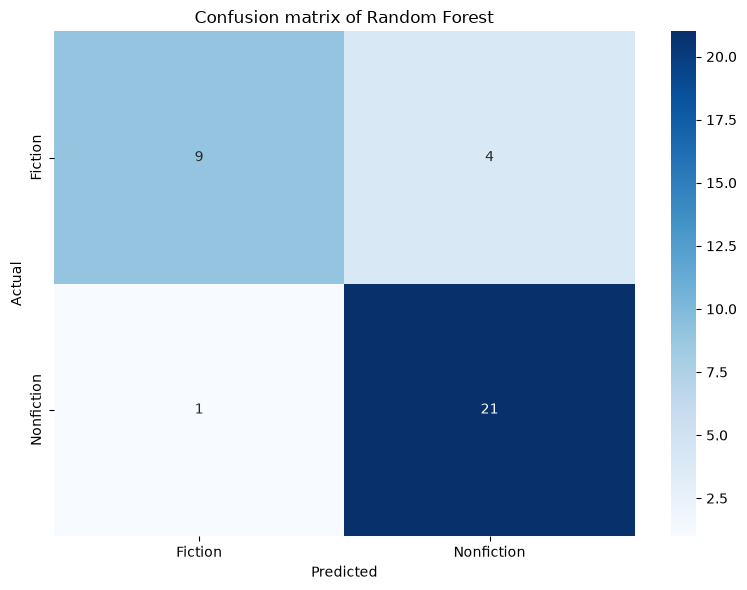

In [20]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

class_labels = sorted(y_test.unique())
cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=class_labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title('Confusion matrix of Random Forest')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()